# MATRIX — Process Timing Diagrams (from averaged states)

Draws the **30-workpiece** timing diagrams from
`results/<experiment-id>/process_states.csv`, the output of
`src/data/timing_data_extractor.py`. All the hard work (glitch removal, trial
validation, per-step averaging) is already done in the extractor — this notebook
just lays each signal's averaged step durations **end-to-end** using the
`cum_start_s` column and draws them as digital waveforms.

Signals are grouped per stage, **actuators first, then sensors** (and the
reported-but-not-gated `rotateToTable` in the transfer stage). Set
`EXPERIMENT_ID` below and Run All.


In [11]:
# --- Configuration -------------------------------------------------------
import os

def _find_base():
    d = os.getcwd()
    for _ in range(6):
        if os.path.isdir(os.path.join(d, "..\results")) or os.path.isdir(os.path.join(d, "database")):
            return d
        p = os.path.dirname(d)
        if p == d:
            break
        d = p
    return os.getcwd()

BASE          = _find_base()
EXPERIMENT_ID = "baseline6wps"
CSV_PATH      = os.path.join(BASE, "results", EXPERIMENT_ID, "process_states.csv")
FIG_DIR       = os.path.join(BASE, "results", EXPERIMENT_ID, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Zoom: set to e.g. (0, 60) to show only the first ~6 workpieces (crisp for the
# paper). None = the full 30-piece run (wide; good for an appendix/overview).
XLIM_S = None

# Which signals appear in each stage panel (top->bottom). Actuators first, then
# the reported motor flag, then sensors. Unknown signals are skipped.
STAGES = {
    "Turntable (Siemens S7-1200)": [
        "sliderMagazine", "motorTurntable", "drillActive", "weldActive",   # actuators
        "turntableInPosition", "magazineEmpty",                            # sensors
    ],
    "Transfer Unit (AB Micro820)": [
        "rotateToConveyor", "vacuumGripper",                               # actuators
        "rotateToTable",                                                   # reported
        "transferUnitAtTurntable", "transferUnitAtConveyor",               # sensors
    ],
    "Conveyor (Schneider TM221)": [
        "conveyorBelt", "separatorValve", "sliderMotor",                   # actuators
        "workpieceOnConveyor", "palletReady", "workpieceOnPallet",         # sensors
        "sliderInPosition",
    ],
}

import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "serif", "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "savefig.bbox": "tight",
})
FULL_W = 7.16

ROLE_COLOR = {"actuator": "#0072B2", "actuator(reported)": "#9467BD", "sensor": "#2CA02C"}

def savefig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))
    print("saved:", name)

print("CSV:", CSV_PATH, "(exists:", os.path.exists(CSV_PATH), ")")

CSV: C:\Users\chabz\Matrix-ICS-Testbed\results\baseline6wps\process_states.csv (exists: True )


In [12]:
# --- Load the averaged states ------------------------------------------
df = pd.read_csv(CSV_PATH)
print(f"loaded {len(df)} rows, {df.signal.nunique()} signals")
roles = df.drop_duplicates("signal").set_index("signal")["role"].to_dict()

# Common end of the time axis = the latest any signal is defined to. Every
# signal's LAST state is then held flat out to this time, so a signal that simply
# stops changing does NOT end mid-plot — it stays at its last value to the edge.
AXIS_END = float(max(
    df[df.signal == s].cum_start_s.iloc[-1] + df[df.signal == s].mean_dur_s.iloc[-1]
    for s in df.signal.unique()))

# Build each signal's step waveform: x = cumulative start times, y = state (0/1).
# A closing point draws the final step's own duration, and a second closing point
# at AXIS_END holds that last state flat to the end of the axis.
def waveform(sig):
    g = df[df.signal == sig].sort_values("step_index")
    if g.empty:
        return None
    xs = g["cum_start_s"].to_numpy()
    ys = g["state"].to_numpy().astype(float)
    own_end = g["cum_start_s"].iloc[-1] + g["mean_dur_s"].iloc[-1]
    # close the last pulse, then extend the held state out to the common axis end
    xs = np.append(xs, [own_end, max(own_end, AXIS_END)])
    ys = np.append(ys, [ys[-1], ys[-1]])
    return xs, ys, g

# Cross-signal drift check: because each signal is averaged on its OWN cumulative
# clock, their total run lengths can differ slightly (the independent-averaging
# construction does not re-synchronise signals). Report the spread so you know how
# far alignment drifts by the end of the 30-piece run.
ends = {s: (df[df.signal == s].cum_start_s.iloc[-1] + df[df.signal == s].mean_dur_s.iloc[-1])
        for s in df.signal.unique()}
emin, emax = min(ends.values()), max(ends.values())
print(f"signal end-times span {emin:.1f}s .. {emax:.1f}s  (cross-signal drift "
      f"over the full run \u2248 {emax-emin:.1f}s)")
print("  -> alignment is tightest early; for a paper figure prefer a zoomed XLIM.")

loaded 193 rows, 17 signals
signal end-times span 101.2s .. 105.4s  (cross-signal drift over the full run ≈ 4.2s)
  -> alignment is tightest early; for a paper figure prefer a zoomed XLIM.


## Stage timing diagrams

One lane per signal; averaged step durations drawn end-to-end. Blue = gating
actuator, purple = reported-but-not-gated actuator (`rotateToTable`), green =
sensor. Set `XLIM_S` above to zoom.


saved: process_timing_stage1


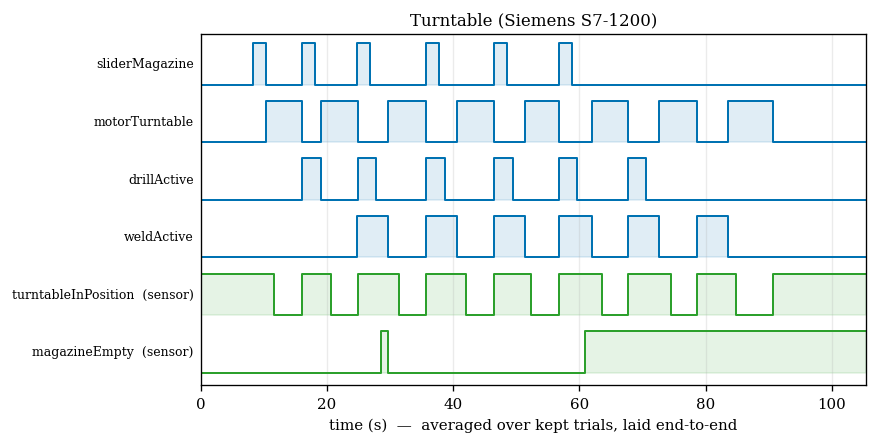

saved: process_timing_stage2


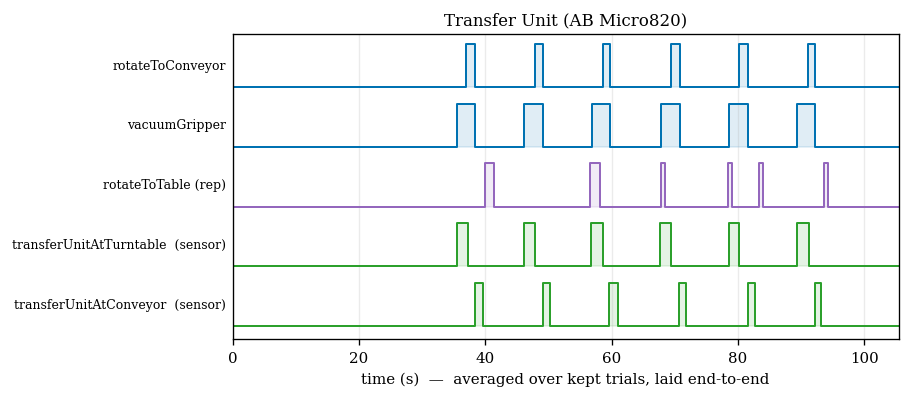

saved: process_timing_stage3


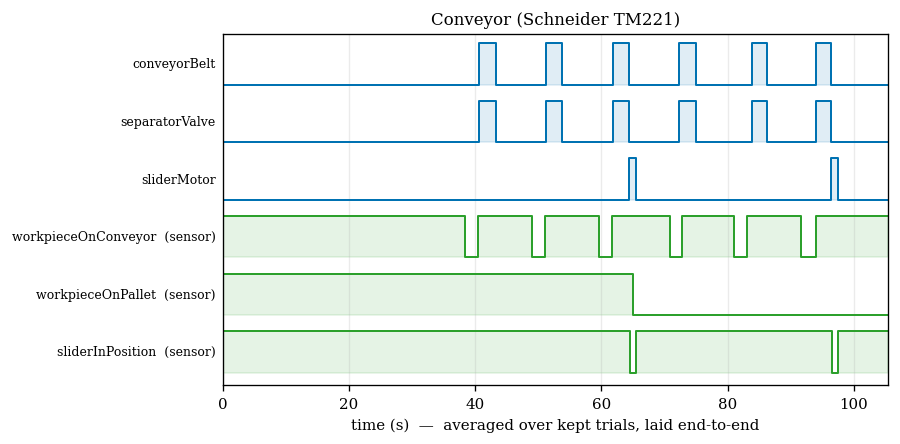

In [13]:
def draw_stage(title, signals, fname):
    rows = [s for s in signals if s in roles]
    if not rows:
        print(f"[{title}] nothing to draw"); return
    fig, ax = plt.subplots(figsize=(FULL_W, 0.5 * len(rows) + 0.8))
    for k, sig in enumerate(rows):
        y0 = len(rows) - 1 - k                      # top-to-bottom
        wf = waveform(sig)
        if wf is None:
            continue
        xs, ys, _ = wf
        col = ROLE_COLOR.get(roles[sig], "#555555")
        y = y0 + 0.12 + 0.72 * ys
        ax.step(xs, y, where="post", color=col, lw=1.2)
        ax.fill_between(xs, y0 + 0.12, y, step="post", color=col, alpha=0.12)
        tag = sig + (" (rep)" if roles[sig].startswith("actuator(rep") else
                     ""   if roles[sig] == "actuator" else "  (sensor)")
        ax.text(-0.01 * (XLIM_S[1] if XLIM_S else emax), y0 + 0.48, tag,
                ha="right", va="center", fontsize=7.5)
    ax.set_ylim(-0.1, len(rows)); ax.set_yticks([])
    ax.set_xlim(*(XLIM_S if XLIM_S else (0, emax)))
    ax.set_xlabel("time (s)  —  averaged over kept trials, laid end-to-end")
    ax.set_title(title); ax.grid(axis="x", alpha=0.25)
    savefig(fig, fname); plt.show()

for i, (title, sigs) in enumerate(STAGES.items(), 1):
    draw_stage(title, sigs, f"process_timing_stage{i}")

saved: process_timing_overview


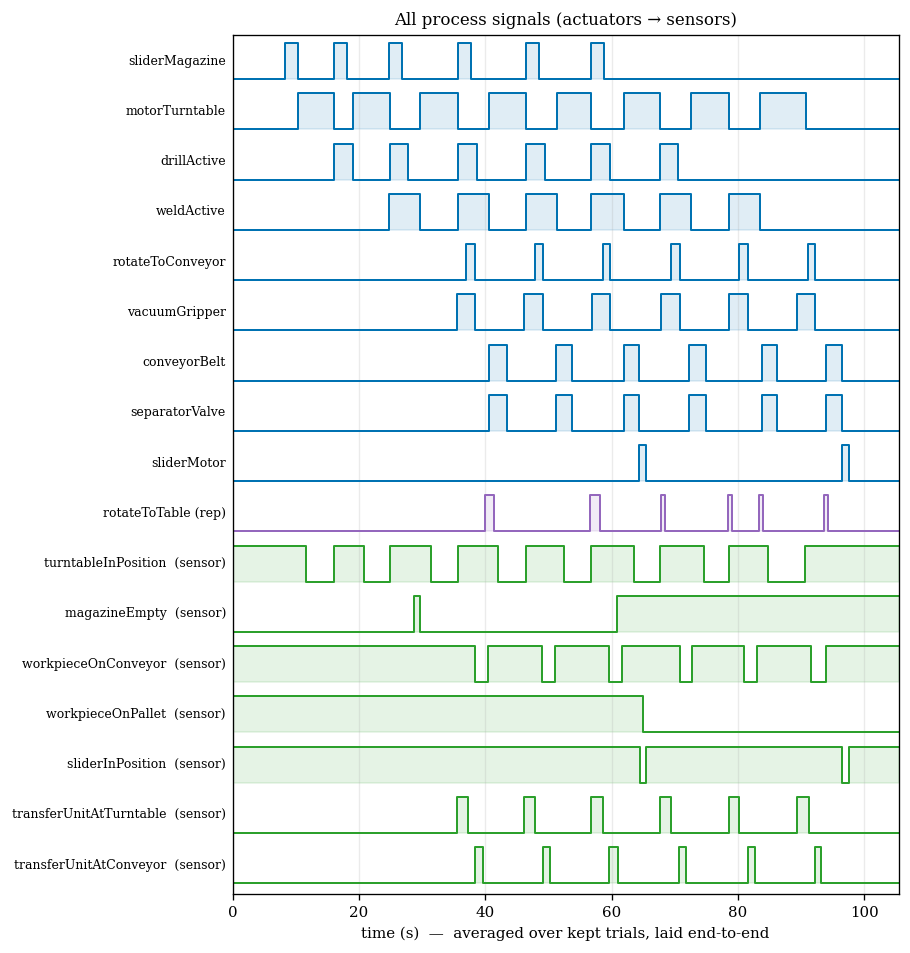

In [14]:
# --- Combined overview: all signals, actuators then reported then sensors
order = (df[df.role == "actuator"].signal.drop_duplicates().tolist()
         + df[df.role == "actuator(reported)"].signal.drop_duplicates().tolist()
         + df[df.role == "sensor"].signal.drop_duplicates().tolist())
draw_stage("All process signals (actuators \u2192 sensors)", order, "process_timing_overview")

## Notes

Figures are in `results/<experiment-id>/figures/`.

**Cross-signal drift.** Each signal is averaged on its own cumulative clock
(per-step durations summed independently), so over 30 pieces the signals can
drift a few seconds relative to each other — alignment is tightest at the start.
This is inherent to the per-signal averaging construction; for a crisp paper
figure, zoom to the first few pieces with `XLIM_S` (e.g. `(0, 60)`). The full-run
overview is best for an appendix.

**Attack overlays (next).** The attack notebook will run the *same* extractor on
the attacked runs, then overlay the attacked waveform on this baseline per signal
and shade the attack window from the Kali `attack_log.json` onset/close — reusing
exactly this plotting machinery.
